# 01 · Modelo de referencia (en horas)

Carga `wolfram/HypothalamusModel.wl`: el modelo completo (4 poblaciones, 3 hormonas, glucosa en 2 compartimentos y 3 receptores) con:
- tiempo en **horas**;
- **corrección** de la corriente de leptina en POMC;
- horarios **periódicos** (cualquier número de días).

Cada simulación se valida contra la referencia en Python (`analysis/reference_model/ref/`), que se obtuvo con el mismo modelo corregido y que ya se verificó contra la versión en segundos.

In [22]:
SetDirectory["~/Documents/22_Neuron_model"];
Get["wolfram/HypothalamusModel.wl"]

HypothalamusModel.wl cargado. Dietas: {TRE, SM, CD, IF}
 
>   . Usa simulate["TRE", 24], plotSim[sim], validate[sim, dir], unitTable.


## Tabla de conversión de unidades (registro)

Magnitud   Original (s)          Nuevo (h)               Conversion

Tiempo t   s                     h                       t_h = t_s/3600

Capacitancia / ecuaciones de voltaje   C = 1 (t en s)        Cm = 1/3600
 
>       dV/dt_h = 3600 dV/dt_s

Constantes de tiempo neuronales (tauK, tauGLU, tauGABA, tauOX, tauInc, tauDec, MC4R,\
 
>    receptores)   s                     h                       tau_h = tau_s/3600

Tasas hormonales (k12, k2x, khx, kix, beta, beta2, theta, rho, epsilon, R0)   num[x] =\
 
>    x/3600 1/s   x 1/h                   se usa x directamente

Ingesta (TRE, CD, IF)   num[2.1] por s        2.1 L/h
 
>    x directamente

Duracion de comidas   2340, 1676, 1400 s    0.650, 0.466, 0.389 h
 
>    /3600

Frecuencia circadiana wc   0.000073 rad/s        0.2628 rad/h
 
>    x 3600

Conductancias, potenciales, EC50, concentraciones   -
 
>    -                       sin cambio
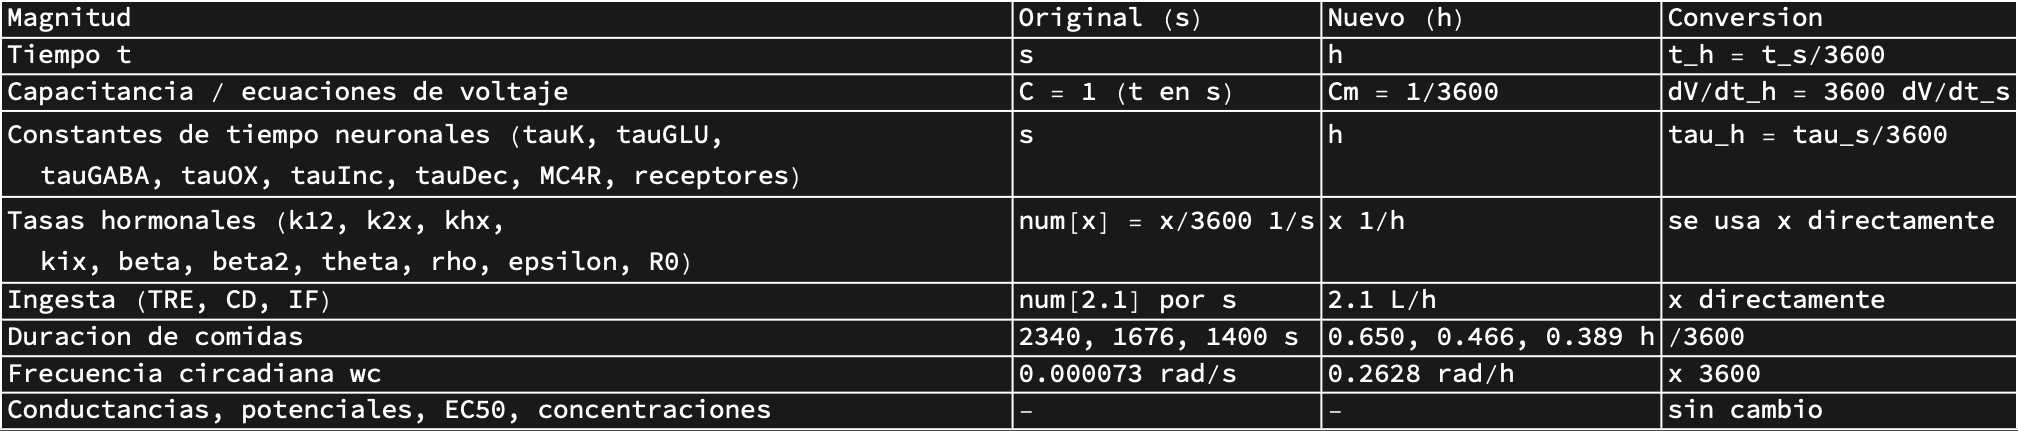

In [24]:
unitTable

## 1. Prueba rápida: la entrada hormonal del modelo, 72 h
El bloque hormonal no depende de las neuronas, así que se puede resolver solo, en segundos. Es la señal que fuerza a la red del modelo completo. Sirve para comprobar que los horarios periódicos funcionan: en IF ahora hay comidas los 3 días.

In [ ]:
hTRE = simulateHormones["TRE", 72];
hIF  = simulateHormones["IF", 72];

Legended[-Graphics-, Placed[LineLegend[{Directive[Opacity[1.], RGBColor[0.24, 0.6, 0.8], 
 
>       AbsoluteThickness[2]], Directive[Opacity[1.], RGBColor[0.95, 0.627, 0.1425], 
 
>       AbsoluteThickness[2]]}, {TRE, IF}, LegendMarkers -> None, LabelStyle -> {}, 
 
>     LegendLayout -> Row], Below, Identity]]
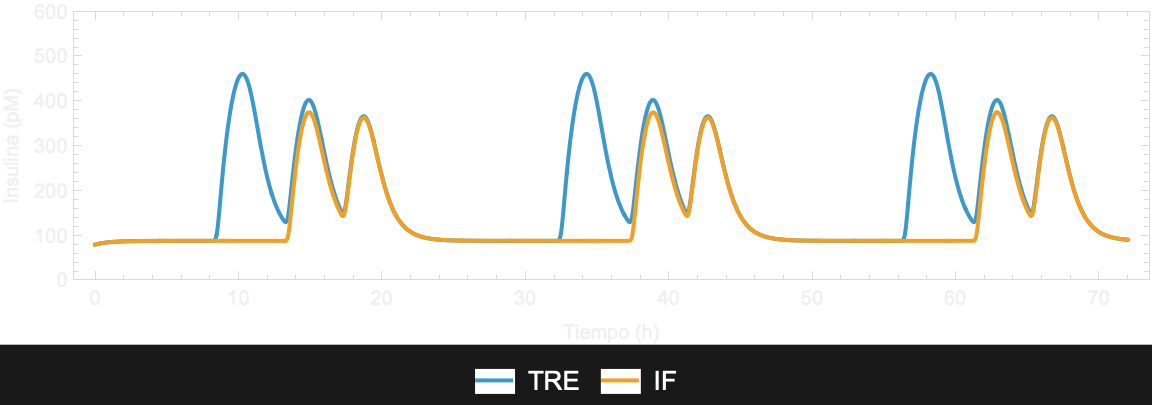

In [28]:
Plot[Evaluate[{INS[h] /. hTRE, INS[h] /. hIF}], {h, 0, 72}, PlotRange -> {0, 600},
 Frame -> True, FrameLabel -> {"Tiempo (h)", "Insulina (pM)"}, PlotLegends -> {"TRE", "IF"},
 ImageSize -> Large, AspectRatio -> 1/4]

## 2. Modelo completo, 3 comidas (TRE), 24 h
Puede tardar unos minutos, porque el solver tiene que resolver cada spike.

{290.001, Null}
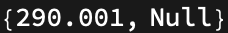

In [10]:
AbsoluteTiming[simTRE = simulate["TRE", 24];]

-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
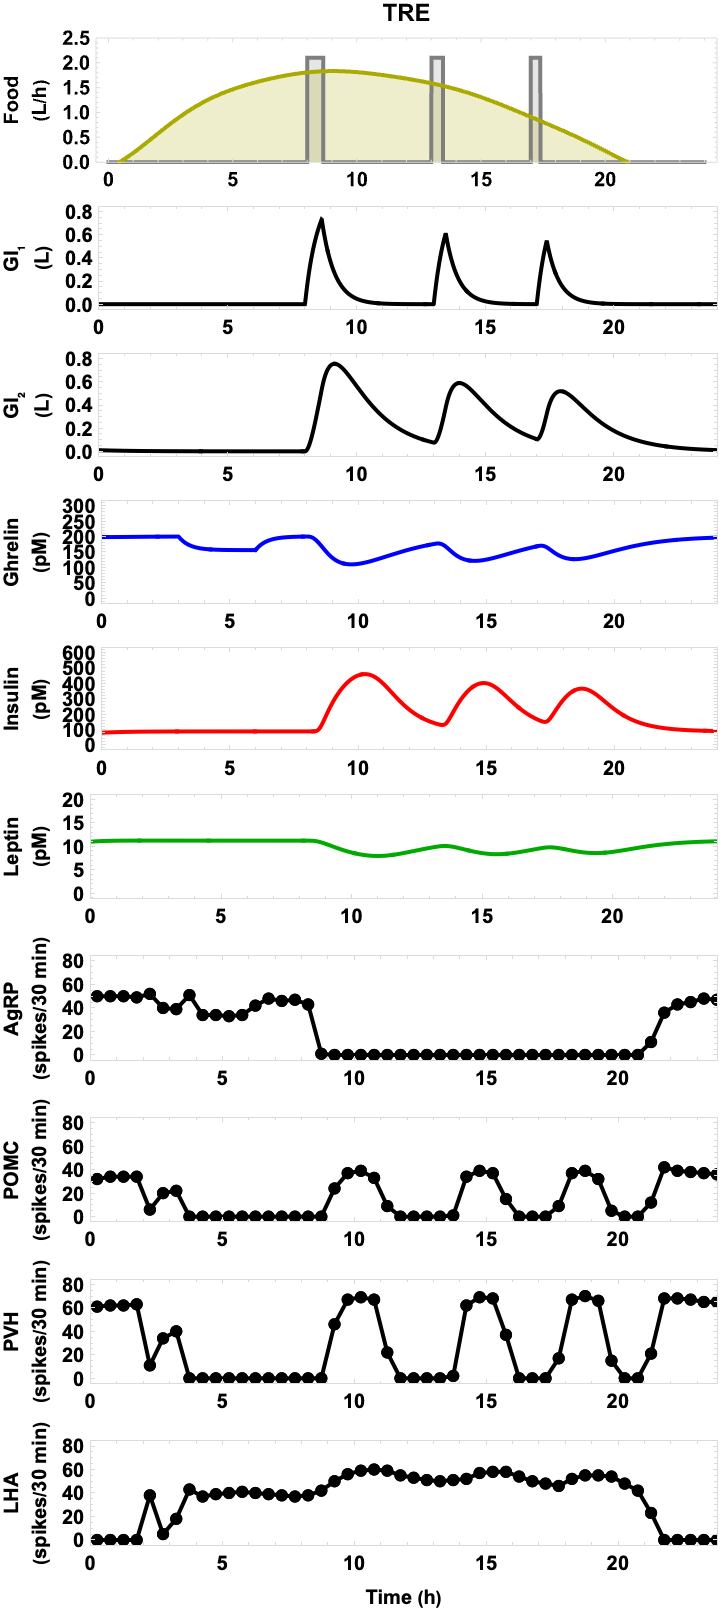

In [25]:
plotSim[simTRE]

-5
Hormonas, error maximo normalizado: 3.7 × 10     OK
Poblacion   Spikes Python   Spikes Wolfram   Dif %   Max dif/bin

AgRP        973             973              0.      1             OK

POMC        776             776              0.      0             OK

PVH         1431            1431             0.      0             OK

LHA         1791            1791             0.      0             OK
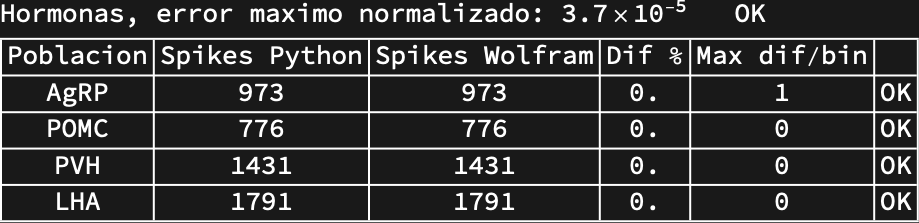

In [26]:
validate[simTRE, "analysis/reference_model/ref"]

## 3. Dieta común (CD), 24 h

{292.672, Null}
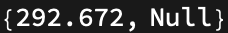

In [27]:
AbsoluteTiming[simCD = simulate["CD", 24];]

-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
-Graphics-
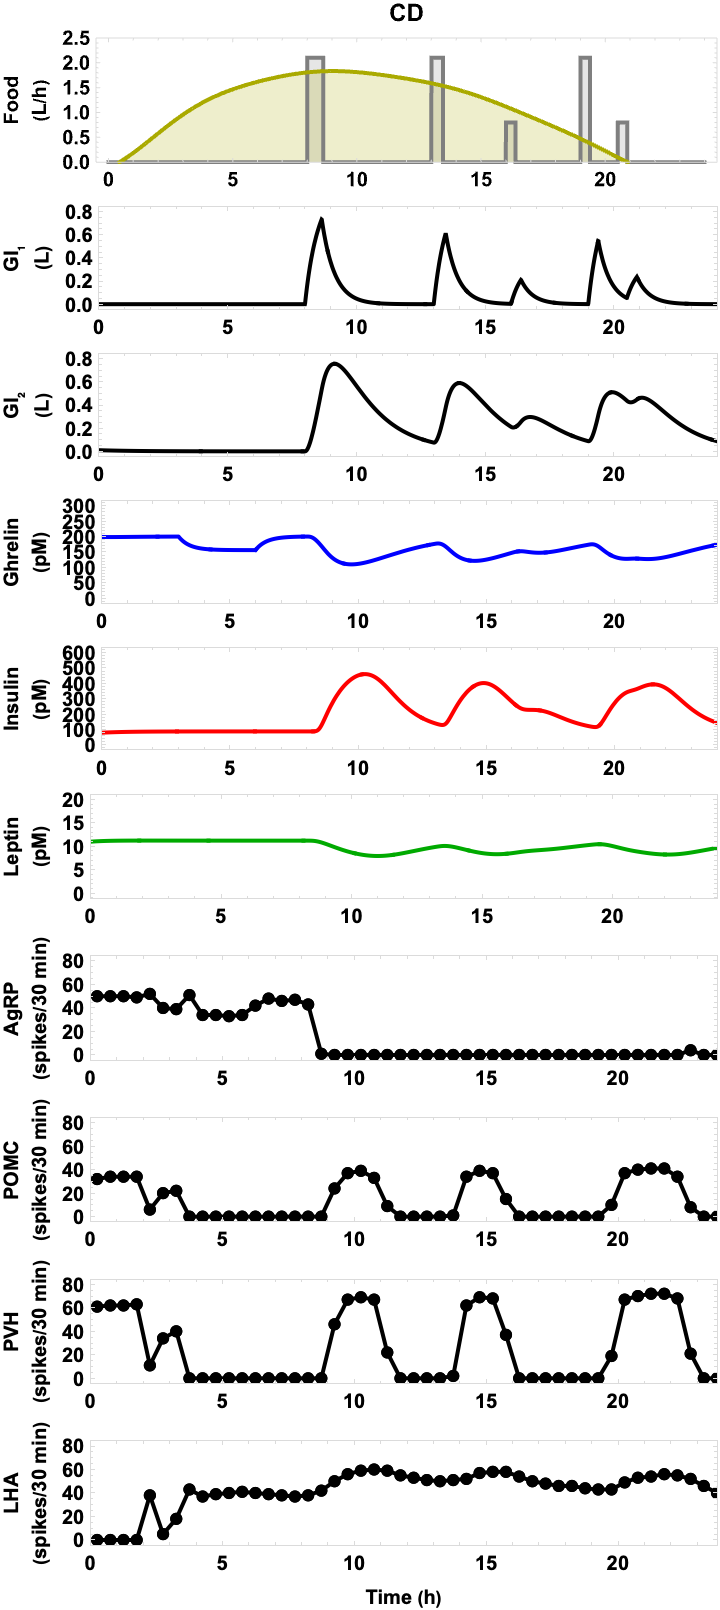

In [29]:
plotSim[simCD]

-4
Hormonas, error maximo normalizado: 3.5 × 10     OK
Poblacion   Spikes Python   Spikes Wolfram   Dif %   Max dif/bin

AgRP        747             747              0.      1             OK

POMC        661             661              0.      0             OK

PVH         1231            1231             0.      0             OK

LHA         2043            2043             0.      0             OK
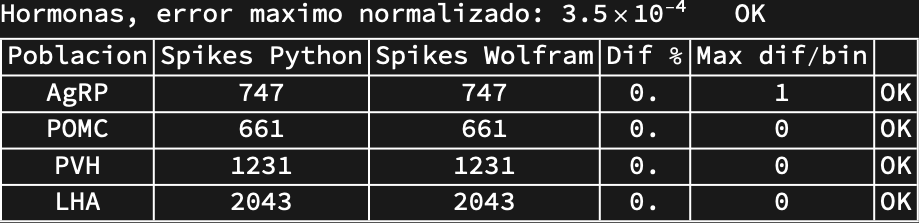

In [30]:
validate[simCD, "analysis/reference_model/ref"]

## 4. Comidas pequeñas (SM) y ayuno intermitente (IF), 24 h

In [31]:
simSM = simulate["SM", 24];
simIF = simulate["IF", 24];

In [ ]:
{validate[simSM, "analysis/reference_model/ref"], validate[simIF, "analysis/reference_model/ref"]}

-Graphics-
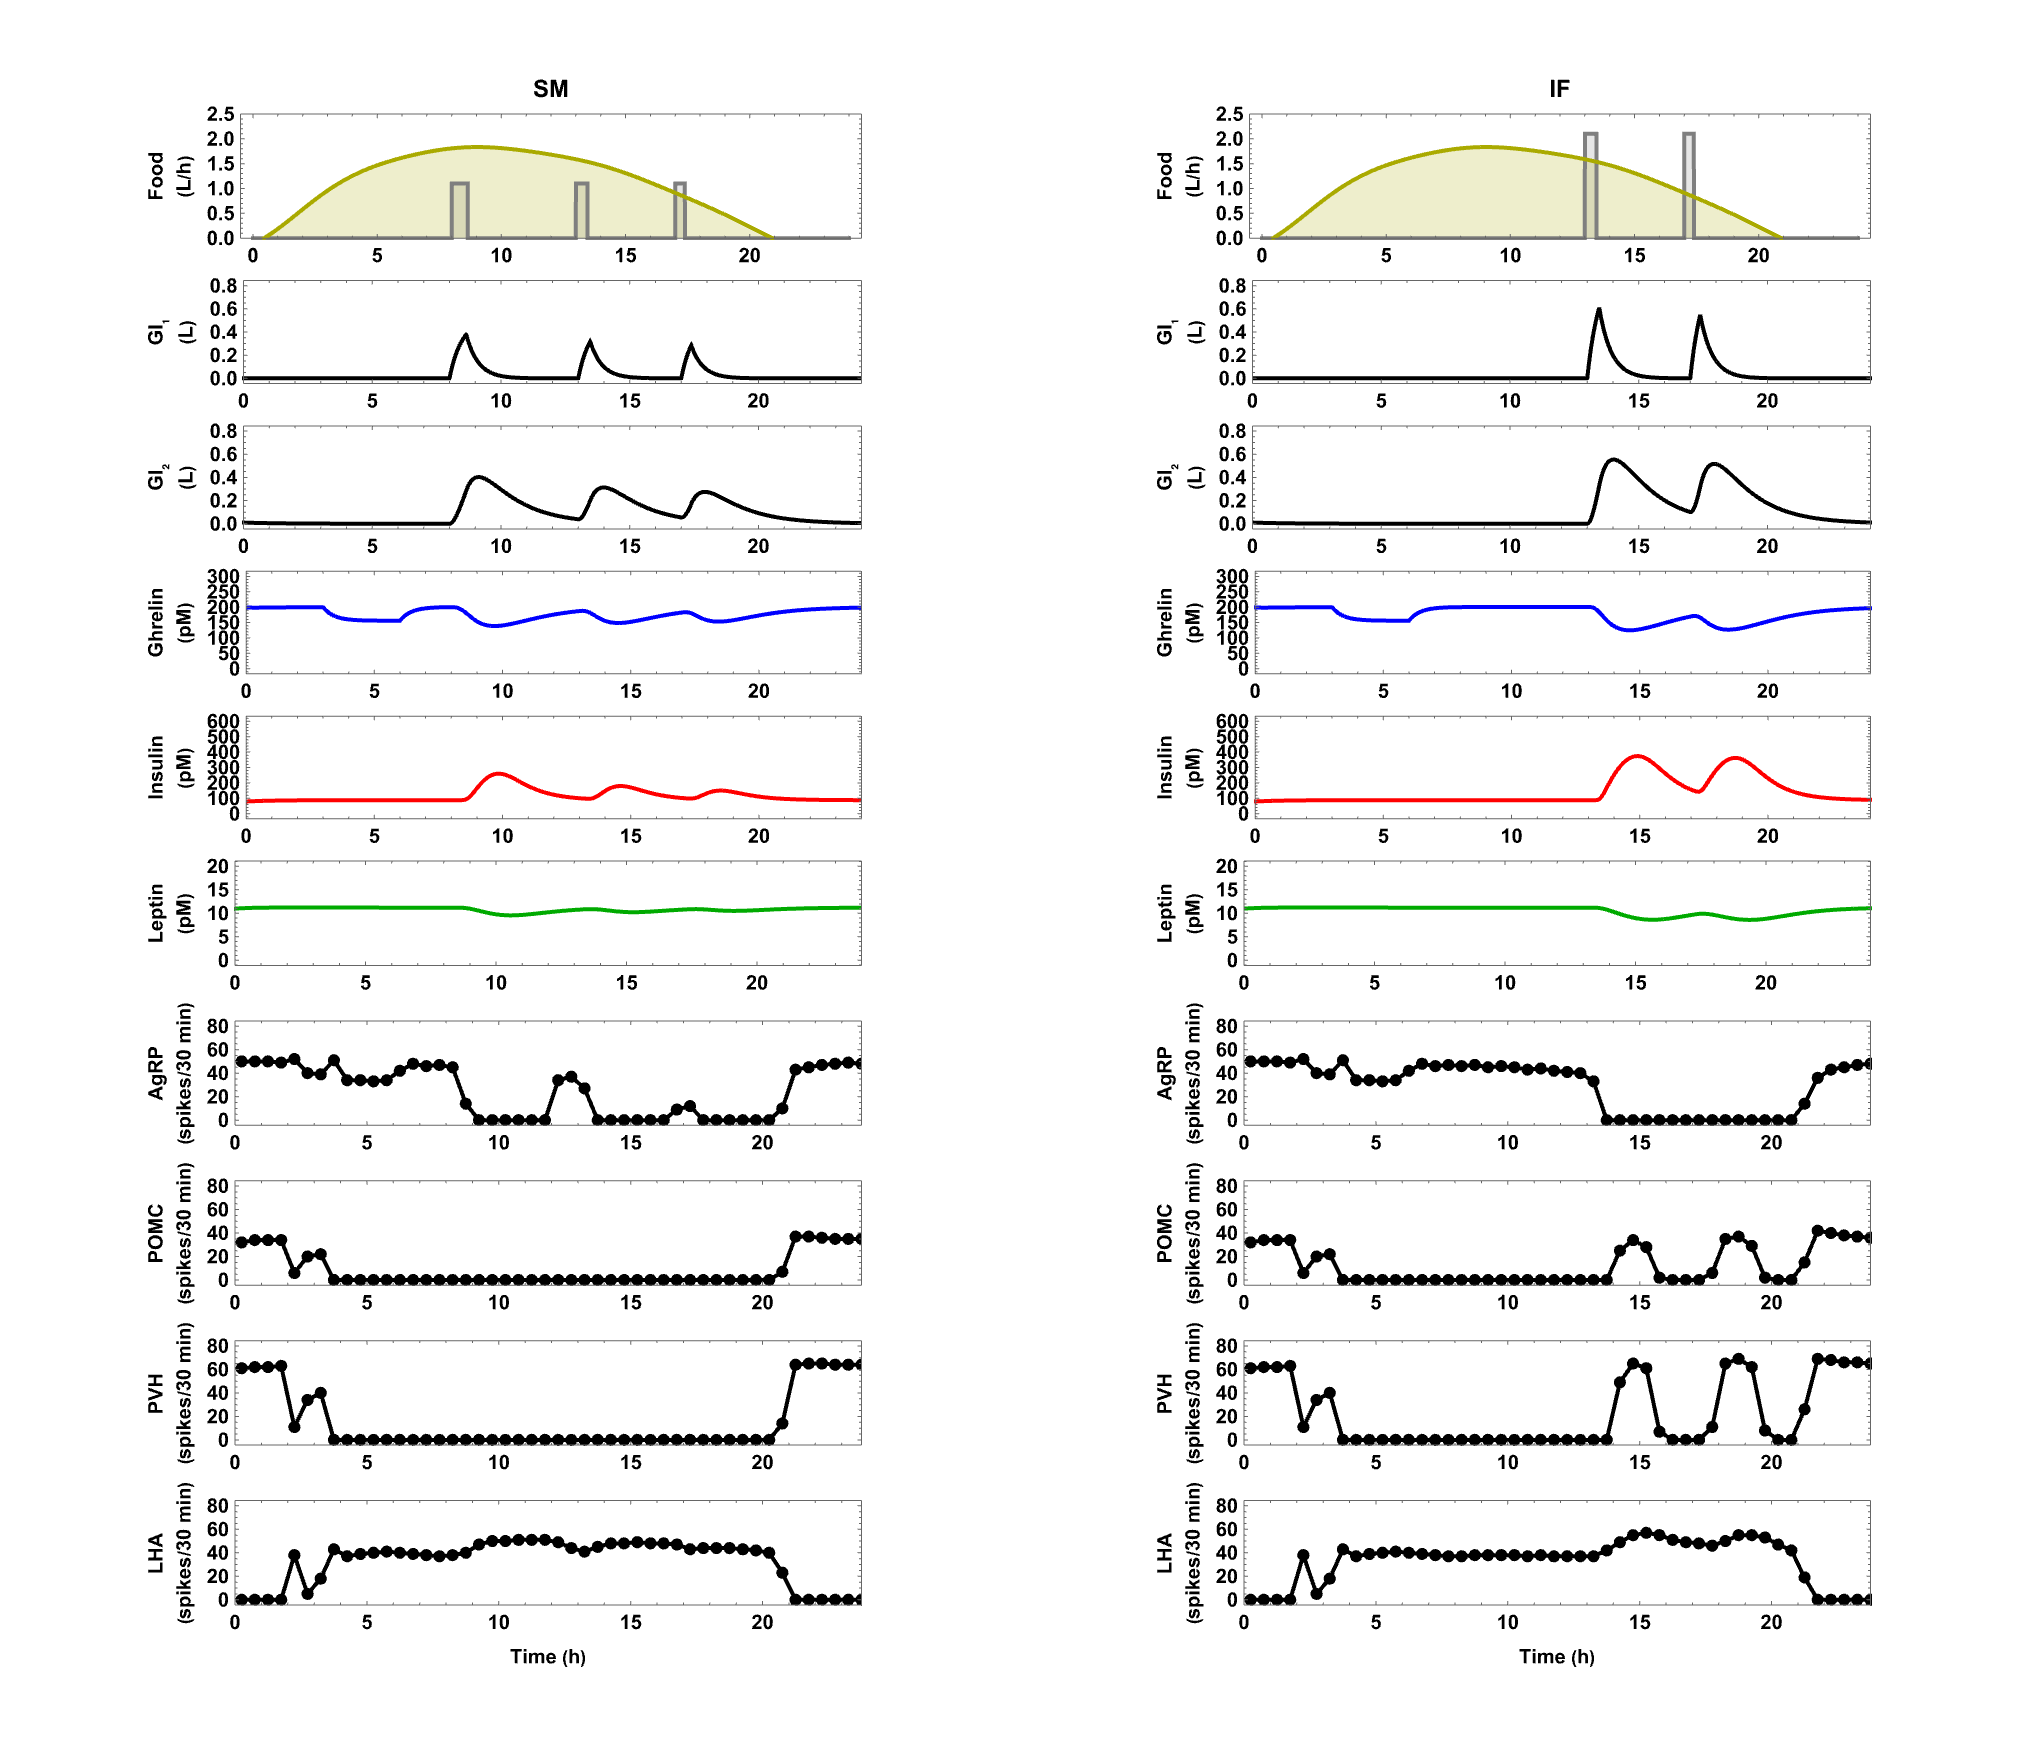

In [33]:
GraphicsRow[{plotSim[simSM], plotSim[simIF]}, ImageSize -> Full]

## 5. Guardar figuras (opcional)

In [ ]:
(* CreateDirectory["figures"];
   Export["figures/ref_TRE_24h.png", plotSim[simTRE], ImageResolution -> 300]; *)

---
**Si alguna validación dice `REVISAR`**, copia la tabla en el chat. Diferencias de pocos spikes por bin son normales (otro integrador, otro paso). Una diferencia sistemática indica un error de conversión.